In [1]:
import pandas as pd 
import numpy as np

In [2]:
df=pd.read_csv(r"C:\Users\emans\OneDrive\Desktop\Assignment Boradway\Titanic-Dataset.csv")

In [3]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
df.shape

(891, 12)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [6]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
df.describe(include='object')

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,B96 B98,S
freq,1,577,7,4,644


In [8]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [9]:
print(df.duplicated().sum())

0


In [10]:
print(df.columns)

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')


In [11]:
df = df.drop(
    columns=["PassengerId", "Ticket", "Cabin"],
    errors="ignore"
)

In [12]:
print(df.columns)

Index(['Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare',
       'Embarked'],
      dtype='object')


### Handling Missing Values 

For Embarked 

In [13]:
df["Embarked"]=df["Embarked"].fillna(df["Embarked"].mode()[0])

Since, there are only 2 value missing, so the most common value is chosen. 

For Age

Imputing on the basis of Name.

In [14]:
df["Title"] = df["Name"].str.extract(r",\s*([^.]+)\.")

In [15]:
df

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Embarked,Title
0,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,7.2500,S,Mr
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,71.2833,C,Mrs
2,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,7.9250,S,Miss
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,53.1000,S,Mrs
4,0,3,"Allen, Mr. William Henry",male,35.0,0,0,8.0500,S,Mr
...,...,...,...,...,...,...,...,...,...,...
886,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,13.0000,S,Rev
887,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,30.0000,S,Miss
888,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,23.4500,S,Miss
889,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,30.0000,C,Mr


In [16]:
df["Age"] = df.groupby("Title")["Age"].transform(lambda x: x.fillna(x.median()))


In [17]:
print(df["Age"].isnull().sum())  #Confirming the age is imputed

0


### EDA

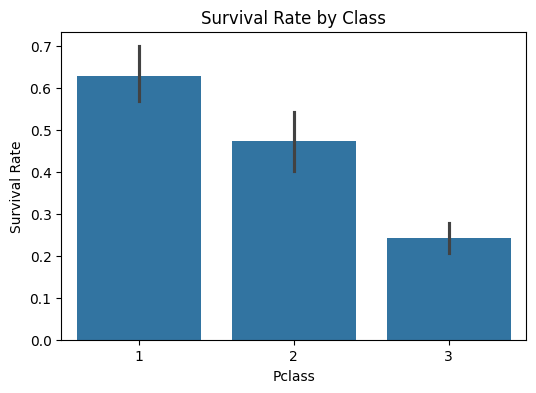

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
sns.barplot(data=df, x='Pclass', y='Survived')
plt.title('Survival Rate by Class')
plt.ylabel('Survival Rate')
plt.show()

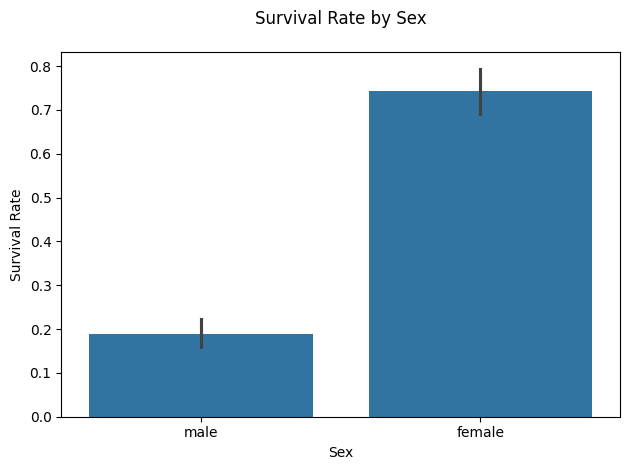

In [19]:
sns.barplot(data=df, x='Sex', y='Survived')
plt.title('Survival Rate by Sex', pad=20)
plt.ylabel('Survival Rate')
plt.tight_layout()
plt.show()

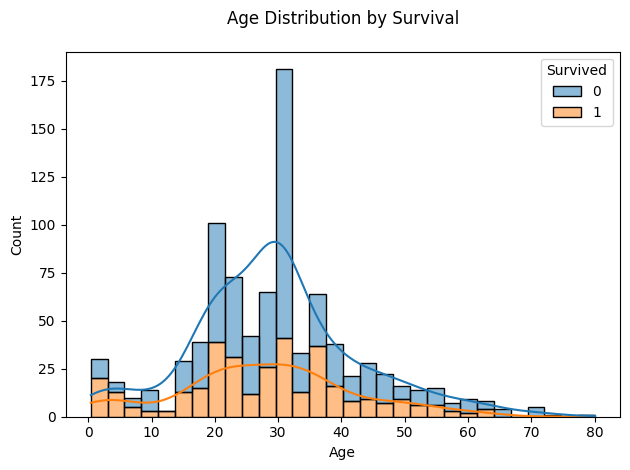

In [20]:
sns.histplot(data=df, x='Age', hue='Survived', kde=True, bins=30, multiple='stack')
plt.title('Age Distribution by Survival', pad=20)
plt.xlabel('Age')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

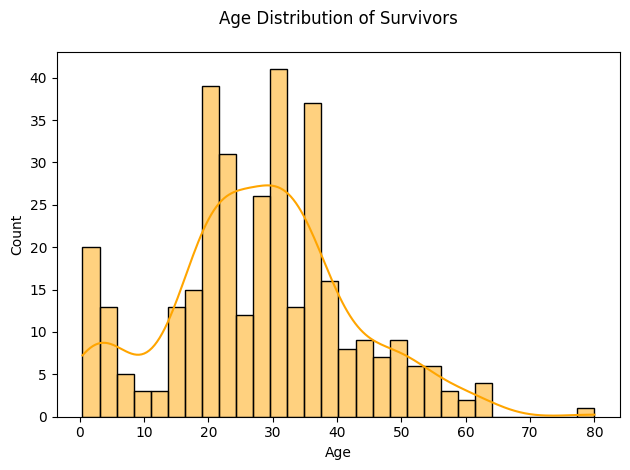

In [21]:
survived_df = df[df['Survived'] == 1]

sns.histplot(data=survived_df, x='Age', kde=True, bins=30, color='orange')
plt.title('Age Distribution of Survivors', pad=20)
plt.xlabel('Age')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

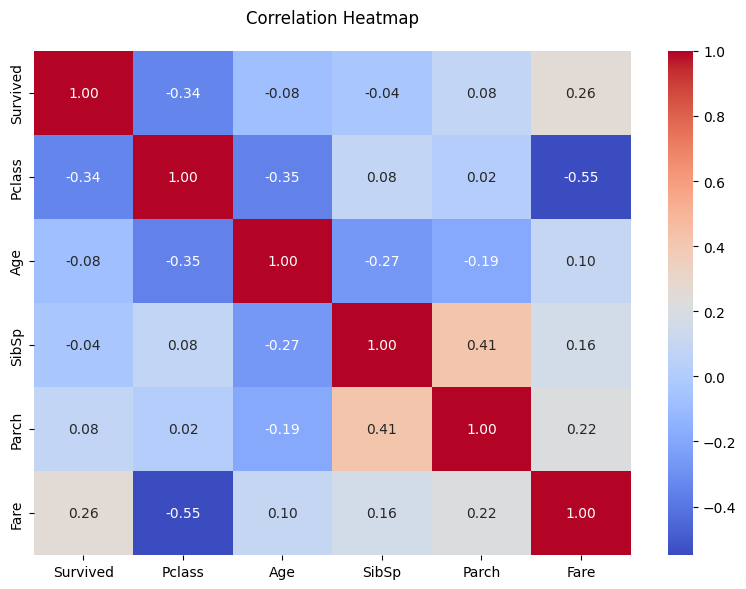

In [22]:
numeric_df = df[['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']]

plt.figure(figsize=(8, 6))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap', pad=20)
plt.tight_layout()
plt.show()

### Splitting

In [23]:
from sklearn.model_selection import train_test_split
df_train, df_test = train_test_split(df, train_size = 0.8, test_size = 0.2, random_state = 42)

In [24]:
df_train.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Embarked,Title
331,0,1,"Partner, Mr. Austen",male,45.5,0,0,28.5000,S,Mr
733,0,2,"Berriman, Mr. William John",male,23.0,0,0,13.0000,S,Mr
382,0,3,"Tikkanen, Mr. Juho",male,32.0,0,0,7.9250,S,Mr
704,0,3,"Hansen, Mr. Henrik Juul",male,26.0,1,0,7.8542,S,Mr
813,0,3,"Andersson, Miss. Ebba Iris Alfrida",female,6.0,4,2,31.2750,S,Miss


In [25]:
df_train.tail()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Embarked,Title
106,1,3,"Salkjelsvik, Miss. Anna Kristine",female,21.0,0,0,7.6500,S,Miss
270,0,1,"Cairns, Mr. Alexander",male,30.0,0,0,31.0000,S,Mr
860,0,3,"Hansen, Mr. Claus Peter",male,41.0,2,0,14.1083,S,Mr
435,1,1,"Carter, Miss. Lucile Polk",female,14.0,1,2,120.0000,S,Miss
102,0,1,"White, Mr. Richard Frasar",male,21.0,0,1,77.2875,S,Mr


In [26]:
print("shape of the train data set : ",df_train.shape)
print("shape of the test data set : ",df_test.shape)

shape of the train data set :  (712, 10)
shape of the test data set :  (179, 10)


### Categorical Features

In [27]:
categorical_features=df_train.select_dtypes(include=['object']).columns.tolist()
categorical_features

['Name', 'Sex', 'Embarked', 'Title']

Name has no predictable value for survival, so we will not use it during column transformer. 

In [28]:
df_train = df_train.drop(columns=['Name'])
df_test = df_test.drop(columns=['Name'])


In [29]:
df_train.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title
331,0,1,male,45.5,0,0,28.5000,S,Mr
733,0,2,male,23.0,0,0,13.0000,S,Mr
382,0,3,male,32.0,0,0,7.9250,S,Mr
704,0,3,male,26.0,1,0,7.8542,S,Mr
813,0,3,female,6.0,4,2,31.2750,S,Miss


In [30]:
df_test.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title
709,1,3,male,3.5,1,1,15.2458,C,Master
439,0,2,male,31.0,0,0,10.5000,S,Mr
840,0,3,male,20.0,0,0,7.9250,S,Mr
720,1,2,female,6.0,0,1,33.0000,S,Miss
39,1,3,female,14.0,1,0,11.2417,C,Miss


### Column Transformer [Feature Scaling and Feature encoding]

Feature Encoding 

In [31]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ct = ColumnTransformer(transformers=[
    ('scale', StandardScaler(), ['Age', 'Fare', 'SibSp', 'Parch']),
    ('ohe', OneHotEncoder(drop='first', handle_unknown='ignore'), ['Sex', 'Embarked', 'Title'])
], remainder='passthrough')  



### Separate features (X) from target (y) 

In [32]:
train_transformed = ct.fit_transform(df_train.drop('Survived', axis=1))   #X_train = train_transformed
test_transformed = ct.transform(df_test.drop('Survived', axis=1))         #X_test = test_transformed

C:\Users\emans\AppData\Roaming\Python\Python313\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Here,drop() is used instead of pop(). 



Only difference is that pop() removes the column from the original DataFrame and returns it,
drop() leaves the original DataFrame unchanged unless assigned the result or use inplace=True.

.drop() doesn't touch df_train, so Survived is still there when we need it later as y_train.If we have used .pop() instead, Survived would already be gone by the time we need.

We need Survived right when you train the model: 
model.fit(train_transformed, df_train['Survived'])

### X_Train

In [33]:
train_transformed 

array([[ 1.22907491, -0.07868358, -0.47072241, ...,  0.        ,
         0.        ,  1.        ],
       [-0.47608723, -0.37714494, -0.47072241, ...,  0.        ,
         0.        ,  2.        ],
       [ 0.20597763, -0.47486697, -0.47072241, ...,  0.        ,
         0.        ,  3.        ],
       ...,
       [ 0.88804248, -0.35580399,  1.23056874, ...,  0.        ,
         0.        ,  3.        ],
       [-1.15815208,  1.68320121,  0.37992316, ...,  0.        ,
         0.        ,  1.        ],
       [-0.6276572 ,  0.86074761, -0.47072241, ...,  0.        ,
         0.        ,  1.        ]])

### X_Test

In [34]:
test_transformed

array([[-1.95389441, -0.33390078,  0.37992316, ...,  0.        ,
         0.        ,  3.        ],
       [ 0.13019264, -0.42528387, -0.47072241, ...,  0.        ,
         0.        ,  2.        ],
       [-0.70344218, -0.47486697, -0.47072241, ...,  0.        ,
         0.        ,  3.        ],
       ...,
       [ 0.66068753, -0.02308312,  0.37992316, ...,  0.        ,
         0.        ,  3.        ],
       [-0.93079713, -0.42528387, -0.47072241, ...,  0.        ,
         0.        ,  2.        ],
       [-1.91600192, -0.30589933,  0.37992316, ...,  0.        ,
         0.        ,  3.        ]])

### Train the logistc regression model 

In [35]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(train_transformed, df_train['Survived'])       # x_train = train_transformed, y_train = df_train['Survived']
y_pred = model.predict(test_transformed)                 # x_test = test_transformed, y_test = df_test['Survived']

### Sanity Check

In [36]:
for i in zip(df_test['Survived'][:10], y_pred[:10]):
    print(f"Actual: {i[0]}, Predicted: {i[1]}")

Actual: 1, Predicted: 1
Actual: 0, Predicted: 0
Actual: 0, Predicted: 0
Actual: 1, Predicted: 1
Actual: 1, Predicted: 1
Actual: 1, Predicted: 1
Actual: 1, Predicted: 1
Actual: 0, Predicted: 0
Actual: 1, Predicted: 1
Actual: 1, Predicted: 1


Printing the first 10 actual vs. predicted results side by side to check how well the model is doing 

### Accuracy

In [37]:
from sklearn.metrics import accuracy_score
accuracy= accuracy_score(df_test['Survived'], y_pred)
print(f"Accuracy: {accuracy:.2f}")

Accuracy: 0.82


### Confusion Matrix 

In [38]:
from sklearn.metrics import confusion_matrix
print(confusion_matrix(df_test['Survived'], y_pred))

[[88 17]
 [16 58]]


Here, 17 pessenger actually died but model wrongly predict as survived .
16 pessenger actually survived but model wrongly predict as died. 

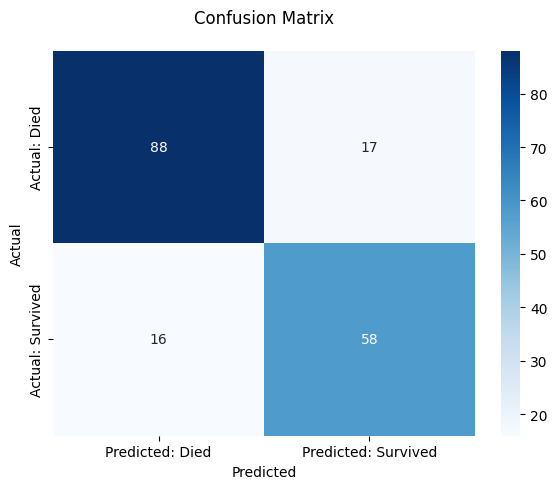

In [39]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(df_test['Survived'], y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted: Died', 'Predicted: Survived'],
            yticklabels=['Actual: Died', 'Actual: Survived'])
plt.title('Confusion Matrix', pad=20)
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

### Classification Report 

In [41]:
from sklearn.metrics import classification_report
print(classification_report(df_test['Survived'], y_pred))

              precision    recall  f1-score   support

           0       0.85      0.84      0.84       105
           1       0.77      0.78      0.78        74

    accuracy                           0.82       179
   macro avg       0.81      0.81      0.81       179
weighted avg       0.82      0.82      0.82       179



All four numbers sit in a fairly tight range (0.77 to 0.85) — no huge gaps between them. It can be considered as "balanced precision/recall".
F-score shows the balanced precision/recall within itself. 

### For class 0 (dead)

Precision 0.85 → when the model says "died," it's right 85% of the time


Recall 0.84 → out of everyone who actually died, the model correctly caught 84% of them

### For class 1 (survived)

Precision 0.77 → when the model says "survived," it's right 77% of the time


Recall 0.78 → out of everyone who actually survived, the model correctly caught 78% of them